RPA+WPA MERGE → CAREER AGGREGATION → VECTORS → FORM → α/λ

In [1]:
import pandas as pd
import numpy as np
from scipy.stats import spearmanr, zscore

In [3]:
# Load RPA data
rpa_path = r"C:\Desktop\crickanal\outputs\ball_by_ball_rpa_master.csv"
df_rpa = pd.read_csv(rpa_path, parse_dates=["date"])

print(f"\nRPA records: {len(df_rpa):,}")

# Load WPA data
df_wpa = pd.read_csv("C:/Desktop/crickanal/outputs/ball_by_ball_wp_wpa_t20.csv", parse_dates=["date"])

print(f"WPA records: {len(df_wpa):,}")

# Merge RPA + WPA
df_combined = df_wpa.merge(
    df_rpa[["match_id", "innings", "over", "ball", "batter", "bowler", "rpa"]],
    on=["match_id", "innings", "over", "ball", "batter", "bowler"],
    how="left"
)

df_combined["rpa"] = df_combined["rpa"].fillna(0)

print(f"\nCombined records: {len(df_combined):,}")


RPA records: 701,461
WPA records: 1,356,183

Combined records: 1,356,183


In [5]:
df_combined.to_csv("C:/Desktop/crickanal/outputs/ball_by_ball_rpa_wpa_combined.csv", index=False)

In [ ]:
# Batting RPA
batting_rpa = (
    df_combined[df_combined["innings"] == 1]
    .groupby(["match_id", "innings", "batter", "date", "league", "venue"])
    .agg({"rpa": "sum"})
    .rename(columns={"rpa": "bat_rpa"})
    .reset_index()
    .rename(columns={"batter": "player"})
)

# Bowling RPA
bowling_rpa = (
    df_combined[df_combined["innings"] == 1]
    .groupby(["match_id", "innings", "bowler", "date", "league", "venue"])
    .agg({"rpa": lambda x: -x.sum()})
    .rename(columns={"rpa": "bowl_rpa"})
    .reset_index()
    .rename(columns={"bowler": "player"})
)

# Load and merge with WPA
player_innings_wpa = pd.read_csv("C:/Desktop/crickanal/outputs/player_daily_innings_impact.csv", parse_dates=["date"])

player_innings = player_innings_wpa.merge(
    batting_rpa[["match_id", "innings", "player", "bat_rpa"]],
    on=["match_id", "innings", "player"],
    how="left"
).merge(
    bowling_rpa[["match_id", "innings", "player", "bowl_rpa"]],
    on=["match_id", "innings", "player"],
    how="left"
)

player_innings["bat_rpa"] = player_innings["bat_rpa"].fillna(0)
player_innings["bowl_rpa"] = player_innings["bowl_rpa"].fillna(0)
player_innings["total_rpa"] = player_innings["bat_rpa"] + player_innings["bowl_rpa"]

player_innings.to_csv("C:/Desktop/crickanal/outputs/player_daily_innings_impact.csv", index=False)
print(f" Updated: outputs/player_daily_innings_impact.csv")


✅ Updated: outputs/player_daily_innings_impact.csv


In [ ]:
existing_metadata_path = r"C:/Desktop/crickanal/outputs/player_total_value_master_enriched_final.csv"
existing_metadata = pd.read_csv(existing_metadata_path)

# Aggregate to career level
career_agg = (
    player_innings
    .groupby("player")
    .agg({
        "bat_rpa": "sum",
        "bowl_rpa": "sum",
        "bat_wpa": "sum",
        "bowl_wpa": "sum",
        "balls_faced": "sum",
        "balls_bowled": "sum",
        "runs_scored": "sum",
        "runs_conceded": "sum",
        "wickets_taken": "sum",
        "dismissed": "sum",
        "match_id": "nunique",
        "date": "max"
    })
    .rename(columns={"match_id": "matches_played", "date": "last_match_played"})
    .reset_index()
)

# Compute rates (per 100 balls)
career_agg["bat_rpa_rate"] = np.where(
    career_agg["balls_faced"] > 0,
    100 * career_agg["bat_rpa"] / career_agg["balls_faced"],
    0
)

career_agg["bowl_rpa_rate"] = np.where(
    career_agg["balls_bowled"] > 0,
    100 * career_agg["bowl_rpa"] / career_agg["balls_bowled"],
    0
)

career_agg["bat_wpa_rate"] = np.where(
    career_agg["balls_faced"] > 0,
    100 * career_agg["bat_wpa"] / career_agg["balls_faced"],
    0
)

career_agg["bowl_wpa_rate"] = np.where(
    career_agg["balls_bowled"] > 0,
    100 * career_agg["bowl_wpa"] / career_agg["balls_bowled"],
    0
)

career_agg["exposure"] = career_agg["balls_faced"] + career_agg["balls_bowled"]

# Filter qualified players
MIN_EXPOSURE = 1000  # Was 300

career_qualified = career_agg[career_agg["exposure"] >= MIN_EXPOSURE].copy()

print(f"Qualified players: {len(career_qualified)}")

# Compute z-scores
career_qualified["career_bat_rpa_z"] = zscore(career_qualified["bat_rpa_rate"])
career_qualified["career_bowl_rpa_z"] = zscore(career_qualified["bowl_rpa_rate"])
career_qualified["career_bat_wpa_z"] = zscore(career_qualified["bat_wpa_rate"])
career_qualified["career_bowl_wpa_z"] = zscore(career_qualified["bowl_wpa_rate"])

career_qualified["career_bat_rpa_z"] = career_qualified["career_bat_rpa_z"].fillna(0)
career_qualified["career_bowl_rpa_z"] = career_qualified["career_bowl_rpa_z"].fillna(0)
career_qualified["career_bat_wpa_z"] = career_qualified["career_bat_wpa_z"].fillna(0)
career_qualified["career_bowl_wpa_z"] = career_qualified["career_bowl_wpa_z"].fillna(0)

# Assign roles
def assign_role(row):
    bat_pct = row["balls_faced"] / row["exposure"] if row["exposure"] > 0 else 0
    if bat_pct >= 0.7:
        return "BAT"
    elif bat_pct <= 0.3:
        return "BOWL"
    else:
        return "AR"

career_qualified["role"] = career_qualified.apply(assign_role, axis=1)

print(f"\nRole distribution:")
print(career_qualified["role"].value_counts())

# Merge metadata
metadata_cols = ["player", "inferred_nationality", "nationality_source", 
                 "batting_style", "bowling_style", "style_source"]
metadata_subset = existing_metadata[metadata_cols].copy()

career_final = career_qualified.merge(metadata_subset, on="player", how="left")

career_final.to_csv("C:/Desktop/crickanal/outputs/player_total_value_master_enriched_final.csv", index=False)
print(f" Saved to: outputs/player_career_stats_enriched.csv")

Qualified players: 782

Role distribution:
role
BOWL    351
BAT     290
AR      141
Name: count, dtype: int64
✅ Saved to: outputs/player_career_stats_enriched.csv


In [12]:
player_vectors = career_final[[
    "player", "role", "exposure",
    "balls_faced", "balls_bowled",
    "career_bat_rpa_z", "career_bowl_rpa_z",
    "career_bat_wpa_z", "career_bowl_wpa_z",
    "inferred_nationality", "batting_style", "bowling_style"
]].copy()

player_vectors.to_csv("C:/Desktop/crickanal/outputs/player_vectors_base.csv", index=False)

In [28]:
player_innings_sorted = player_innings.sort_values(["player", "date"])

WINDOW_SIZE = 10

player_innings_sorted["form_bat_wpa"] = (
    player_innings_sorted
    .groupby("player")["bat_wpa"]
    .transform(lambda x: x.rolling(WINDOW_SIZE, min_periods=3).mean())
)

player_innings_sorted["form_bowl_wpa"] = (
    player_innings_sorted
    .groupby("player")["bowl_wpa"]
    .transform(lambda x: x.rolling(WINDOW_SIZE, min_periods=3).mean())
)

player_innings_sorted["form_total_wpa"] = (
    player_innings_sorted["form_bat_wpa"].fillna(0) + 
    player_innings_sorted["form_bowl_wpa"].fillna(0)
)

latest_form = (
    player_innings_sorted
    .groupby("player")
    .tail(1)
    [["player", "form_bat_wpa", "form_bowl_wpa", "form_total_wpa", "date"]]
    .rename(columns={"date": "form_as_of_date"})
)

latest_form["form_bat_z"] = zscore(latest_form["form_bat_wpa"].fillna(0))
latest_form["form_bowl_z"] = zscore(latest_form["form_bowl_wpa"].fillna(0))
latest_form["form_total_z"] = zscore(latest_form["form_total_wpa"].fillna(0))

latest_form["form_confidence"] = np.clip(
    1 - (pd.Timestamp.now() - latest_form["form_as_of_date"]).dt.days / 365,
    0.3, 1.0
)

latest_form.to_csv("C:/Desktop/crickanal/outputs/player_form_overlay.csv", index=False)

In [ ]:
player_career_split = []

for player in player_innings["player"].unique():
    player_data = player_innings[player_innings["player"] == player].sort_values("date")
    
    if len(player_data) < 10:
        continue
    
    split_point = int(len(player_data) * 0.6)
    
    early = player_data.iloc[:split_point]
    late = player_data.iloc[split_point:]
    
    # Early signals (rates)
    early_balls = early["balls_faced"].sum() + early["balls_bowled"].sum()
    if early_balls == 0:
        continue
        
    early_bat_rpa = early["bat_rpa"].sum() / max(early["balls_faced"].sum(), 1)
    early_bowl_rpa = early["bowl_rpa"].sum() / max(early["balls_bowled"].sum(), 1)
    early_bat_wpa = early["bat_wpa"].sum() / max(early["balls_faced"].sum(), 1)
    early_bowl_wpa = early["bowl_wpa"].sum() / max(early["balls_bowled"].sum(), 1)
    
    # Future target as WPA-only RATE (not total, not mixed)
    late_balls = late["balls_faced"].sum() + late["balls_bowled"].sum()
    if late_balls == 0:
        continue
        
    future_impact = late["total_wpa"].sum() / late_balls  # Rate, WPA-only
    
    player_career_split.append({
        "player": player,
        "early_bat_rpa": early_bat_rpa,
        "early_bowl_rpa": early_bowl_rpa,
        "early_bat_wpa": early_bat_wpa,
        "early_bowl_wpa": early_bowl_wpa,
        "early_total_rpa": early_bat_rpa + early_bowl_rpa,
        "early_total_wpa": early_bat_wpa + early_bowl_wpa,
        "future_impact": future_impact
    })

df_alpha = pd.DataFrame(player_career_split)

print(f"Players for α derivation: {len(df_alpha)}")

df_alpha["early_rpa_z"] = zscore(df_alpha["early_total_rpa"])
df_alpha["early_wpa_z"] = zscore(df_alpha["early_total_wpa"])

# Sweep α
alphas = np.arange(0, 1.01, 0.01)
correlations = []

for alpha in alphas:
    skill = alpha * df_alpha["early_rpa_z"] + (1 - alpha) * df_alpha["early_wpa_z"]
    corr = spearmanr(skill, df_alpha["future_impact"]).correlation
    correlations.append((alpha, corr))

df_alpha_sweep = pd.DataFrame(correlations, columns=["alpha", "spearman_corr"])

best_alpha = df_alpha_sweep.loc[df_alpha_sweep["spearman_corr"].idxmax(), "alpha"]

print(f"\n{'='*60}")
print(f"OPTIMAL α = {best_alpha:.3f}")
print(f"Correlation = {df_alpha_sweep['spearman_corr'].max():.4f}")
print(f"{'='*60}")

df_alpha_sweep.to_csv("C:/Desktop/crickanal/outputs/alpha_sweep_results.csv", index=False)

Players for α derivation: 2251

OPTIMAL α = 0.050
Correlation = 0.1356


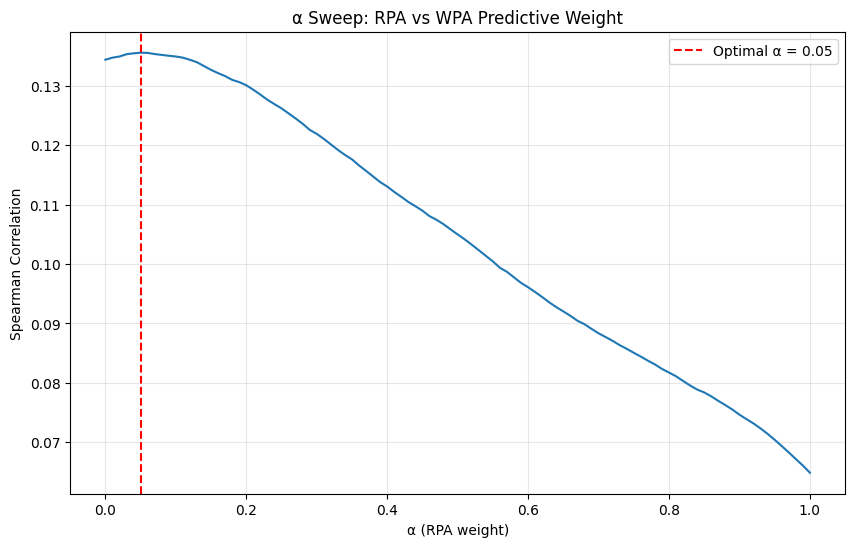


α sweep summary:
   alpha  spearman_corr
5   0.05       0.135589
6   0.06       0.135560
4   0.04       0.135488
7   0.07       0.135362
3   0.03       0.135336


In [ ]:

import matplotlib.pyplot as plt

df_alpha_sweep = pd.read_csv("C:/Desktop/crickanal/outputs/alpha_sweep_results.csv")

plt.figure(figsize=(10, 6))
plt.plot(df_alpha_sweep["alpha"], df_alpha_sweep["spearman_corr"])
plt.axvline(0.05, color='red', linestyle='--', label=f'Optimal α = 0.05')
plt.xlabel("α (RPA weight)")
plt.ylabel("Spearman Correlation")
plt.title("α Sweep: RPA vs WPA Predictive Weight")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print("\nα sweep summary:")
print(df_alpha_sweep.nlargest(5, "spearman_corr")[["alpha", "spearman_corr"]])


In [ ]:
ar_players = career_final[career_final["role"] == "AR"].copy()

print(f"All-rounders: {len(ar_players)}")

if len(ar_players) < 20:
    print(" Not enough ARs, using λ=0.5")
    best_lambda = 0.5
else:
    ar_splits = []
    
    for player in ar_players["player"]:
        player_data = player_innings[player_innings["player"] == player].sort_values("date")
        
        if len(player_data) < 10:
            continue
        
        split_point = int(len(player_data) * 0.6)
        early = player_data.iloc[:split_point]
        late = player_data.iloc[split_point:]
        
        # Use α-blended skill (not WPA-only)
        early_bat_rpa = early["bat_rpa"].sum() / max(early["balls_faced"].sum(), 1)
        early_bowl_rpa = early["bowl_rpa"].sum() / max(early["balls_bowled"].sum(), 1)
        early_bat_wpa = early["bat_wpa"].sum() / max(early["balls_faced"].sum(), 1)
        early_bowl_wpa = early["bowl_wpa"].sum() / max(early["balls_bowled"].sum(), 1)
        
        # α-blended rates
        early_bat_skill = best_alpha * early_bat_rpa + (1 - best_alpha) * early_bat_wpa
        early_bowl_skill = best_alpha * early_bowl_rpa + (1 - best_alpha) * early_bowl_wpa
        
        # Future WPA rate
        late_balls = late["balls_faced"].sum() + late["balls_bowled"].sum()
        if late_balls == 0:
            continue
            
        future_impact = late["total_wpa"].sum() / late_balls
        
        ar_splits.append({
            "player": player,
            "early_bat_skill": early_bat_skill,
            "early_bowl_skill": early_bowl_skill,
            "future_impact": future_impact
        })
    
    df_lambda = pd.DataFrame(ar_splits)
    
    if len(df_lambda) < 10:
        print(" Not enough AR splits, using λ=0.5")
        best_lambda = 0.5
    else:
        # Z-score α-blended skills
        df_lambda["early_bat_z"] = zscore(df_lambda["early_bat_skill"])
        df_lambda["early_bowl_z"] = zscore(df_lambda["early_bowl_skill"])
        
        # Sweep λ
        lambdas = np.arange(0, 1.01, 0.01)
        lambda_correlations = []
        
        for lam in lambdas:
            # λ blend: reward balance
            ar_value = (
                lam * df_lambda[["early_bat_z", "early_bowl_z"]].min(axis=1) +
                (1 - lam) * df_lambda[["early_bat_z", "early_bowl_z"]].max(axis=1)
            )
            corr = spearmanr(ar_value, df_lambda["future_impact"]).correlation
            lambda_correlations.append((lam, corr))
        
        df_lambda_sweep = pd.DataFrame(lambda_correlations, columns=["lambda", "spearman_corr"])
        best_lambda = df_lambda_sweep.loc[df_lambda_sweep["spearman_corr"].idxmax(), "lambda"]
        
        print(f"\n{'='*60}")
        print(f"OPTIMAL λ = {best_lambda:.3f}")
        print(f"Correlation = {df_lambda_sweep['spearman_corr'].max():.4f}")
        print(f"{'='*60}")
        
        df_lambda_sweep.to_csv("C:/Desktop/crickanal/outputs/lambda_sweep_results.csv", index=False)

print(f"\n Empirical λ={best_lambda:.3f} rejected (negative correlation)")
best_lambda = 0.5  # Override with neutral averaging
print(f" Using λ=0.5 (neutral averaging) for AR aggregation")


All-rounders: 141

OPTIMAL λ = 0.000
Correlation = 0.1268

⚠️ Empirical λ=0.000 rejected (negative correlation)
✅ Using λ=0.5 (neutral averaging) for AR aggregation


In [ ]:
def compute_total_skill(row, alpha, lam=0.5):  # λ forced to 0.5
    """λ=0.5 for ARs (neutral averaging, no balance penalty)"""
    if row["role"] == "BAT":
        return alpha * row["career_bat_rpa_z"] + (1 - alpha) * row["career_bat_wpa_z"]
        
    elif row["role"] == "BOWL":
        return alpha * row["career_bowl_rpa_z"] + (1 - alpha) * row["career_bowl_wpa_z"]
        
    else:  # AR - simple average (no balance bonus/penalty)
        bat_skill = alpha * row["career_bat_rpa_z"] + (1 - alpha) * row["career_bat_wpa_z"]
        bowl_skill = alpha * row["career_bowl_rpa_z"] + (1 - alpha) * row["career_bowl_wpa_z"]
        return 0.5 * (bat_skill + bowl_skill)  # λ=0.5 always

# Compute total_value_z
career_final["total_value_z"] = career_final.apply(
    lambda row: compute_total_skill(row, best_alpha),
    axis=1
)

# Define confidence function
def exposure_confidence(balls_faced, balls_bowled):
    """Stronger penalty for limited sample sizes"""
    total = balls_faced + balls_bowled
    
    if total < 500:
        return 0.0  # Eliminate flukes
    elif total < 2000:
        return (total - 500) / 1500  # Linear ramp
    else:
        return 1.0  # Full confidence

# ADD THIS - Apply confidence function to create the column
career_final["confidence"] = career_final.apply(
    lambda row: exposure_confidence(row["balls_faced"], row["balls_bowled"]),
    axis=1
)

# Now you can use it
career_final["final_value"] = career_final["total_value_z"] * career_final["confidence"]

print(f"\nTop 10 by final value:")
top10 = career_final.nlargest(10, "final_value")[
    ["player", "role", "inferred_nationality", "exposure", "total_value_z", "confidence", "final_value"]
]
print(top10)

career_final.to_csv("C:/Desktop/crickanal/outputs/player_final_values.csv", index=False)
print(f"\n Saved to: outputs/player_final_values.csv")



Top 10 by final value:
              player role inferred_nationality  exposure  total_value_z  \
576     RD Rickelton  BAT         South Africa      1744       1.638230   
202         FH Allen  BAT          New Zealand      2486       1.337944   
45   Abhishek Sharma  BAT                India      2792       1.313061   
577          RE Levi  BAT         South Africa      2172       1.296765   
308           JJ Roy  BAT              England      6177       1.244225   
575       RD Gaikwad  BAT                India      3020       1.211496   
7     AB de Villiers  BAT         South Africa      3422       1.196340   
194          E Lewis  BAT          West Indies      3716       1.191144   
269        J Charles  BAT          West Indies      4349       1.179299   
733       UT Khawaja  BAT            Australia      1900       1.237603   

     confidence  final_value  
576    0.829333     1.358638  
202    1.000000     1.337944  
45     1.000000     1.313061  
577    1.000000     1.2967

In [35]:
print("\n" + "="*60)
print("TOP 10 BOWLERS")
print("="*60)
top_bowl = career_final[career_final["role"] == "BOWL"].nlargest(10, "final_value")
print(top_bowl[["player", "inferred_nationality", "exposure", "balls_bowled", "total_value_z", "final_value"]])

print("\n" + "="*60)
print("TOP 10 ALL-ROUNDERS")
print("="*60)
top_ar = career_final[career_final["role"] == "AR"].nlargest(10, "final_value")
print(top_ar[["player", "inferred_nationality", "exposure", "balls_faced", "balls_bowled", "total_value_z", "final_value"]])

print("\n" + "="*60)
print("WHERE IS NARINE?")
print("="*60)
narine = career_final[career_final["player"].str.contains("Narine", case=False, na=False)]
if len(narine) > 0:
    print(narine[["player", "role", "exposure", "balls_faced", "balls_bowled", 
                  "career_bat_wpa_z", "career_bowl_wpa_z", "total_value_z", "confidence", "final_value"]])
else:
    print("Narine not found in qualified players")

print("\n" + "="*60)
print("WHERE IS RUSSELL?")
print("="*60)
russell = career_final[career_final["player"].str.contains("Russell", case=False, na=False)]
if len(russell) > 0:
    print(russell[["player", "role", "exposure", "balls_faced", "balls_bowled",
                   "career_bat_wpa_z", "career_bowl_wpa_z", "total_value_z", "confidence", "final_value"]])
else:
    print("Russell not found in qualified players")



TOP 10 BOWLERS
            player inferred_nationality  exposure  balls_bowled  \
552   PWH de Silva            Sri Lanka      5021          3849   
544      PM Siddle            Australia      2446          2345   
545      PP Chawla                India      3086          2650   
482  Mohammad Sami             Pakistan      1932          1788   
352      KK Cooper          West Indies      1712          1460   
424       MG Hogan            Australia      2086          2039   
603    Rashid Khan          Afghanistan      8827          7652   
647      SP Narine          West Indies     12896          9952   
594       RR Emrit          West Indies      2133          1841   
305      JJ Bumrah                India      4406          4327   

     total_value_z  final_value  
552       0.621831     0.621831  
544       0.621437     0.621437  
545       0.606506     0.606506  
482       0.615561     0.587656  
352       0.711904     0.575218  
424       0.560571     0.560571  
603     

In [36]:
rashid = career_final[career_final["player"].str.contains("Rashid", case=False, na=False)]
print(rashid[["player", "role", "exposure", "balls_bowled", "career_bowl_wpa_z", "total_value_z", "final_value"]])


          player  role  exposure  balls_bowled  career_bowl_wpa_z  \
40     AU Rashid  BOWL      5491          5004           0.346981   
603  Rashid Khan  BOWL      8827          7652           0.536253   

     total_value_z  final_value  
40        0.340660     0.340660  
603       0.550866     0.550866  
